# Dự đoán giao trễ — Manual balance và SMOTE

Tải notebook lên Colab/Kaggle/Jupyter, bật Internet và **Run All**.
Không cần PostgreSQL hay clone repo. Chạy Logistic Regression, Random Forest,
LightGBM với các thiết lập tốt nhất đã kiểm chứng trong những lượt thử trước.

**Pipeline:** Olist → ETL pandas → 5-fold stratified → cân bằng train bằng
**Manual 2:1** hoặc **SMOTE 10k+10k** → cùng test 50:50 chỉ gồm đơn thật.
Seed 42. Manual chỉ giảm mẫu lớp đúng hạn, không tạo mẫu tổng hợp.
Manual dùng ngưỡng 0,5; SMOTE giữ các ngưỡng validation trong bảng dưới.
Có thêm bảng so sánh cả hai tại ngưỡng 0,5 để đối chiếu cân bằng dữ liệu.

Config và ngưỡng đã được chọn trên validation trước đây, lưu cố định theo fold;
Run All chỉ huấn luyện lại, không chạy tuning và không chọn lại bằng test.

| Model | Thiết lập đã chọn | Ngưỡng fold 1–5 | F1 OOF tham khảo |
|---|---|---|---:|
| Logistic Regression | C: 1; 1; 10; 0,001; 0,1 | 0,25; 0,35; 0,25; 0,35; 0,30 | 0,6696 |
| Random Forest | 300 cây, max_features=0,7 | 0,25; 0,20; 0,20; 0,25; 0,20 | 0,7132 |
| LightGBM | 100 cây, LR=0,03, 63 lá, min_child=100, colsample=0,7 | 0,25 mỗi fold | 0,7155 |

Đây là thử nghiệm tiếp nối trên cùng Olist v2/seed/fold, chưa phải xác nhận độc lập.
Thiết lập theo fold không phải một model triển khai; không tự áp các ngưỡng này
cho dữ liệu khác. Lượt tìm kiếm mới không vượt các kết quả trên.

Paper: [Hartman et al., ICICT 2026](https://doi.org/10.1145/3803291.3803322).
Dữ liệu: [Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce),
CC BY-NC-SA 4.0. Paper không mô tả đủ cách dựng 20.000 mẫu; ở đây áp mốc này
cho mỗi train fold, không khẳng định tái lập chính xác bài báo.


In [1]:
import sys
import subprocess

# Pin sklearn / imbalanced-learn; giữ numpy/pandas tương thích đã có trên host.
subprocess.check_call(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "--quiet",
        "--disable-pip-version-check",
        "numpy>=1.26,<3",
        "pandas>=2.2,<3",
        "scikit-learn==1.6.1",
        "imbalanced-learn==0.14.0",
        "lightgbm==4.6.0",
        "kagglehub==0.4.3",
        "matplotlib>=3.8,<4",
    ]
)


0

In [2]:
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
N_SPLITS = 5
OUTPUT = Path("late_risk_results/balance_comparison")
OUTPUT.mkdir(parents=True, exist_ok=True)


C:\Users\ducph\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Tải dữ liệu

Dùng CSV trong `data/raw` nếu có; nếu chưa có thì tải bộ Olist phiên bản 2 qua
KaggleHub. Nếu Kaggle yêu cầu xác thực, cần cấp quyền cho phiên notebook.

In [3]:
FILES = {
    "orders": "olist_orders_dataset.csv",
    "items": "olist_order_items_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "products": "olist_products_dataset.csv",
    "geo": "olist_geolocation_dataset.csv",
    "translation": "product_category_name_translation.csv",
}
candidates = [
    Path("data/raw"),
    Path("../data/raw"),
    Path("/kaggle/input/brazilian-ecommerce"),
]
DATA = next(
    (p for p in candidates if all((p / f).is_file() for f in FILES.values())),
    None,
)
if DATA is None:
    DATA = Path(
        kagglehub.dataset_download("olistbr/brazilian-ecommerce/versions/2")
    )
missing = [f for f in FILES.values() if not (DATA / f).is_file()]
if missing:
    raise FileNotFoundError(f"Thiếu CSV trong {DATA}: {missing}")
raw = {
    name: pd.read_csv(DATA / filename, dtype="string", encoding="utf-8-sig")
    for name, filename in FILES.items()
}
print("Nguồn dữ liệu:", DATA)
display(
    pd.DataFrame({"table": raw.keys(), "rows": [len(t) for t in raw.values()]})
)


Nguồn dữ liệu: C:\Users\ducph\.cache\kagglehub\datasets\olistbr\brazilian-ecommerce\versions\2


,table,rows
0,orders,99441
1,items,112650
2,customers,99441
3,sellers,3095
4,products,32951
5,geo,1000163
6,translation,71


## 2. Tiền xử lý theo ETL của repo

- Ép kiểu lỗi thành null, giữ ZIP dạng chuỗi, bỏ geo trùng/outlier và lấy median tọa độ.
- Danh mục thiếu → unknown; khối lượng 0 → null; bỏ dòng item thiếu giá.
- Một dòng mỗi đơn: phí vận chuyển cộng tổng, khoảng cách lấy lớn nhất,
  physical score cộng theo item; category lấy mode. Đây là các giả định gom item.
- Nhãn trễ so **ngày nhận > ngày hẹn**, không so giờ; chỉ dùng đơn có nhãn và đủ
  đặc trưng. Giữ cờ bất thường để kiểm tra, không đưa các cờ/ngày nhận/ID vào model.
- Physical score = weight × height × length × width / 1000.

Chỉ dựng phần ETL cần cho ML, không dựng warehouse, payment hoặc review.

In [4]:
def transform(raw):
    tables = {name: frame.copy() for name, frame in raw.items()}
    audit = []

    def log(step, count):
        audit.append({"check": step, "rows": int(count)})

    def numeric(frame, columns):
        for col in columns:
            source = frame[col]
            frame[col] = pd.to_numeric(source, errors="coerce").astype(float)
            log(
                f"invalid_numeric:{col}",
                (source.notna() & frame[col].isna()).sum(),
            )

    o, i, p = tables["orders"], tables["items"], tables["products"]
    c, s, g, tr = (
        tables[k] for k in ["customers", "sellers", "geo", "translation"]
    )
    dates = [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
    ]
    for col in dates:
        source = o[col]
        o[col] = pd.to_datetime(source, errors="coerce", format="mixed")
        log(f"invalid_date:{col}", (source.notna() & o[col].isna()).sum())
    for frame, key in [
        (o, "order_id"),
        (p, "product_id"),
        (c, "customer_id"),
        (s, "seller_id"),
    ]:
        assert (
            frame[key].notna().all() and frame[key].is_unique
        ), f"Khóa lỗi: {key}"
    assert tr.product_category_name.is_unique, "Bảng dịch trùng category"
    numeric(i, ["price", "freight_value"])
    physical = [
        "product_weight_g",
        "product_length_cm",
        "product_height_cm",
        "product_width_cm",
    ]
    numeric(p, physical)
    p["product_weight_g"] = p.product_weight_g.mask(p.product_weight_g.eq(0))
    p["item_physical_score"] = p[physical].prod(axis=1, min_count=4) / 1000
    translations = tr.set_index(
        "product_category_name"
    ).product_category_name_english.to_dict()
    translations.setdefault("pc_gamer", "pc_gamer")
    translations.setdefault(
        "portateis_cozinha_e_preparadores_de_alimentos",
        "portable_kitchen_and_food_preparers",
    )
    category = p.product_category_name.fillna("unknown")
    p["product_category_name"] = category.map(translations).where(
        category.ne("unknown"), "unknown"
    )

    before = len(g)
    g = g.drop_duplicates().copy()
    log("duplicate_geo_removed", before - len(g))
    numeric(g, ["geolocation_lat", "geolocation_lng"])
    g["zip"] = g.geolocation_zip_code_prefix.str.zfill(5)
    inside = g.geolocation_lat.between(-33.8, 5.3) & g.geolocation_lng.between(
        -74, -34.7
    )
    log("geo_outside_bbox_or_missing", (~inside).sum())
    # R18: ZIP không có tọa độ hợp lệ vẫn có thể join, nhưng tọa độ giữ null.
    geo = (
        g.loc[inside]
        .groupby("zip")[["geolocation_lat", "geolocation_lng"]]
        .median()
        .round(6)
    )
    for frame, prefix in [(c, "customer"), (s, "seller")]:
        frame["zip"] = frame[f"{prefix}_zip_code_prefix"].str.zfill(5)
        coords = geo.rename(
            columns={
                "geolocation_lat": f"{prefix}_lat",
                "geolocation_lng": f"{prefix}_lng",
            }
        )
        joined = frame.join(coords, on="zip", validate="many_to_one")
        if prefix == "customer":
            c = joined
        else:
            s = joined

    log("items_missing_price_removed", i.price.isna().sum())
    i = i.loc[i.price.notna()].copy()
    log(
        "orders_missing_purchase_removed",
        o.order_purchase_timestamp.isna().sum(),
    )
    o = o.loc[o.order_purchase_timestamp.notna()].copy()
    delivered, estimated = (
        o.order_delivered_customer_date,
        o.order_estimated_delivery_date,
    )
    purchased, approved, carrier = (
        o.order_purchase_timestamp,
        o.order_approved_at,
        o.order_delivered_carrier_date,
    )
    o["delay_days"] = (
        delivered.dt.normalize() - estimated.dt.normalize()
    ).dt.days
    o["is_late"] = o.delay_days.gt(0).where(
        delivered.notna() & estimated.notna()
    )
    o["has_missing_milestone"] = o.order_status.eq("delivered") & (
        approved.isna() | carrier.isna() | delivered.isna()
    )
    o["has_time_anomaly"] = (
        (carrier < purchased)
        | (carrier < approved)
        | (delivered < carrier)
        | (o.order_status.ne("delivered") & delivered.notna())
    )
    o["shipping_days_estimated"] = (
        (estimated - purchased).dt.total_seconds() / 86400
    ).round(2)
    o.loc[estimated < purchased, "shipping_days_estimated"] = np.nan
    o["order_weekday"] = purchased.dt.dayofweek
    o["order_purchase_month"] = purchased.dt.month

    rows = (
        i.merge(
            o[["order_id", "customer_id"]],
            on="order_id",
            validate="many_to_one",
        )
        .merge(
            p[["product_id", "product_category_name", "item_physical_score"]],
            on="product_id",
            how="left",
            validate="many_to_one",
        )
        .merge(
            s[["seller_id", "seller_lat", "seller_lng"]],
            on="seller_id",
            how="left",
            validate="many_to_one",
        )
        .merge(
            c[["customer_id", "customer_lat", "customer_lng"]],
            on="customer_id",
            how="left",
            validate="many_to_one",
        )
    )
    lat_s, lon_s, lat_c, lon_c = [
        np.radians(rows[col].astype(float))
        for col in ["seller_lat", "seller_lng", "customer_lat", "customer_lng"]
    ]
    a = (
        np.sin((lat_c - lat_s) / 2) ** 2
        + np.cos(lat_s) * np.cos(lat_c) * np.sin((lon_c - lon_s) / 2) ** 2
    )
    rows["distance_km"] = 2 * 6371 * np.arcsin(np.sqrt(a.clip(0, 1)))
    group = rows.groupby("order_id", sort=False)
    features = group.agg(
        freight_value=("freight_value", "sum"),
        distance_km=("distance_km", "max"),
        item_physical_score=("item_physical_score", "sum"),
    )
    for col in features:
        features.loc[group[col].count().lt(group.size()), col] = np.nan
    categories = (
        rows.dropna(subset=["product_category_name"])
        .groupby(["order_id", "product_category_name"])
        .size()
        .rename("n")
        .reset_index()
        .sort_values(
            ["order_id", "n", "product_category_name"],
            ascending=[True, False, True],
        )
        .drop_duplicates("order_id")
        .set_index("order_id")
        .product_category_name
    )
    features["product_category_name"] = categories
    fact = o.merge(features, on="order_id", how="left", validate="one_to_one")
    labeled = fact.loc[fact.is_late.notna()].copy()
    log("warehouse_orders", len(fact))
    log("unlabeled_orders_excluded_from_ML", len(fact) - len(labeled))
    static = [
        "distance_km",
        "freight_value",
        "shipping_days_estimated",
        "order_weekday",
        "order_purchase_month",
        "product_category_name",
        "item_physical_score",
    ]
    data = labeled.dropna(subset=static).reset_index(drop=True)
    log("labeled_missing_static_features_excluded", len(labeled) - len(data))
    log("retained_time_anomaly", data.has_time_anomaly.sum())
    log("retained_missing_milestone", data.has_missing_milestone.sum())
    data["is_late"] = data.is_late.astype(int)
    links = rows[["order_id", "seller_id"]].drop_duplicates()
    assert links.seller_id.notna().all(), "Seller bị thiếu"
    assert data.order_id.is_unique
    assert np.isfinite(
        data[[x for x in static if x != "product_category_name"]].to_numpy(
            float
        )
    ).all()
    return data, links, pd.DataFrame(audit)


In [5]:
data, links, audit = transform(raw)
assert data.order_id.is_unique
assert set(data.is_late.unique()) == {0, 1}
display(audit.loc[audit.rows.ne(0)])
display(data.is_late.value_counts().rename_axis("late").to_frame("orders"))
audit.to_csv(OUTPUT / "etl_audit.csv", index=False)

expected = (
    data.order_delivered_customer_date.dt.normalize()
    > data.order_estimated_delivery_date.dt.normalize()
).astype(int)
assert data.is_late.equals(expected)


,check,rows
11,duplicate_geo_removed,261831
14,geo_outside_bbox_or_missing,33
17,warehouse_orders,99441
18,unlabeled_orders_excluded_from_ML,2965
19,labeled_missing_static_features_excluded,503
20,retained_time_anomaly,1372
21,retained_missing_milestone,15


,orders
late,
0,89483
1,6490


## 3. Lịch sử người bán

Chỉ dùng đơn thuộc train đã biết kết quả trước lúc mua đơn đang dự đoán;
`known_at = max(ngày nhận, ngày hẹn)`. Seller mới điền 0; nhiều seller lấy trung bình.
Không dùng nhãn test hoặc nhãn của chính đơn đó để tạo đặc trưng.

In [6]:
HISTORY = [
    "delayed_orders_by_seller",
    "delay_rate_percent_by_seller",
    "seller_avg_delay_days",
]
NUMERIC = [
    "distance_km",
    "freight_value",
    "shipping_days_estimated",
    "order_weekday",
    "order_purchase_month",
    "item_physical_score",
] + HISTORY
CATEGORICAL = ["product_category_name"]


def seller_history(query, train, links):
    events = train[
        [
            "order_id",
            "order_delivered_customer_date",
            "order_estimated_delivery_date",
            "is_late",
            "delay_days",
        ]
    ].copy()
    events["known_at"] = events[
        ["order_delivered_customer_date", "order_estimated_delivery_date"]
    ].max(axis=1)
    events = events.merge(links, on="order_id", validate="one_to_many")
    # Gộp đồng thời trước cumsum: mọi event tại cùng thời điểm cùng được biết.
    events = events.groupby(["seller_id", "known_at"], as_index=False).agg(
        n=("is_late", "size"),
        late=("is_late", "sum"),
        total_delay=("delay_days", "sum"),
    )
    events = events.sort_values(["known_at", "seller_id"])
    cols = ["n", "late", "total_delay"]
    events[cols] = events.groupby("seller_id")[cols].cumsum()
    queries = query[["order_id", "order_purchase_timestamp"]].merge(
        links, on="order_id", validate="one_to_many"
    )
    queries = queries.sort_values(["order_purchase_timestamp", "seller_id"])
    past = pd.merge_asof(
        queries,
        events,
        by="seller_id",
        left_on="order_purchase_timestamp",
        right_on="known_at",
        direction="backward",
        allow_exact_matches=False,
    )
    past[cols] = past[cols].fillna(0)
    past[HISTORY[0]] = past.late
    past[HISTORY[1]] = (100 * past.late / past.n.replace(0, np.nan)).fillna(0)
    past[HISTORY[2]] = (past.total_delay / past.n.replace(0, np.nan)).fillna(0)
    history = past.groupby("order_id")[HISTORY].mean()
    result = query.drop(columns=HISTORY, errors="ignore").join(
        history, on="order_id", validate="one_to_one"
    )
    assert result[HISTORY].notna().all().all(), "Đơn thiếu lịch sử seller"
    return result


## 4. Chạy ba model × hai cách cân bằng × 5 fold

Mỗi lượt dùng 80% đơn thật làm train; từ 20% còn lại giữ mọi đơn trễ và chọn cùng
số đơn đúng hạn làm test 50:50. Ba model dùng cùng index train/test.

Train Manual: giữ mọi đơn trễ thật, chọn số đơn đúng hạn gấp 2 lần số đơn trễ
(theo mục 3.2/Algorithm 2 của paper). Train SMOTE: giữ mọi đơn trễ thật, chọn
10.000 đơn đúng hạn, SMOTE lớp trễ lên 10.000. Hai nhánh dùng cùng config;
config được lấy từ lượt tuning SMOTE trước đó, chưa tuning riêng Manual.
Encoding chỉ fit train; SMOTE trước scaler như paper, chỉ LR scale các cột số.
SMOTE trên one-hot có thể tạo category dạng phân số và chịu ảnh hưởng đơn vị đo.

Sau mỗi model/fold, in **Precision, Recall, F1 và Support** riêng cho hai lớp
**On time (0)** và **Late (1)**. Support là số đơn thực tế của mỗi lớp trong test.


In [7]:
models = {
    "Logistic Regression": LogisticRegression(
        C=1, max_iter=2000, random_state=SEED
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_features=0.7, n_jobs=-1, random_state=SEED
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=100,
        learning_rate=0.03,
        num_leaves=63,
        min_child_samples=100,
        colsample_bytree=0.7,
        n_jobs=2,
        verbosity=-1,
        random_state=SEED,
    ),
}
# Các giá trị đã chọn trên validation, tương ứng fold 1 đến 5.
LR_C = [1, 1, 10, 0.001, 0.1]
THRESHOLDS = {
    "Logistic Regression": [0.25, 0.35, 0.25, 0.35, 0.30],
    "Random Forest": [0.25, 0.20, 0.20, 0.25, 0.20],
    "LightGBM": [0.25] * 5,
}
assert N_SPLITS == len(LR_C) == 5
assert all(len(values) == N_SPLITS for values in THRESHOLDS.values())

y = data.is_late.to_numpy(int)
folds = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
records, predictions = [], []

for fold, (train_idx, test_idx) in enumerate(folds.split(data, y), 1):
    rng = np.random.default_rng(SEED + fold)
    late = test_idx[y[test_idx] == 1]
    ontime = test_idx[y[test_idx] == 0]
    assert 0 < len(late) <= len(ontime)
    test_idx = np.sort(
        np.r_[late, rng.choice(ontime, len(late), replace=False)]
    )
    assert not np.intersect1d(train_idx, test_idx).size
    assert len(test_idx) == len(np.unique(test_idx))
    assert np.bincount(y[test_idx]).tolist() == [len(late), len(late)]

    train, test = data.iloc[train_idx], data.iloc[test_idx]
    encoder = ColumnTransformer(
        [
            ("numeric", "passthrough", NUMERIC),
            (
                "category",
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                CATEGORICAL,
            ),
        ]
    )
    train_features = seller_history(train, train, links)
    test_features = seller_history(test, train, links)
    x_train = encoder.fit_transform(
        train_features[NUMERIC + CATEGORICAL]
    ).astype(np.float32)
    x_test = encoder.transform(test_features[NUMERIC + CATEGORICAL]).astype(
        np.float32
    )

    x_original = x_train
    for balance in ["Manual 2:1", "SMOTE 10k+10k"]:
        if balance == "Manual 2:1":
            sampler = RandomUnderSampler(
                sampling_strategy=0.5, random_state=SEED
            )
            x_train, y_train = sampler.fit_resample(x_original, y[train_idx])
            counts = np.bincount(y_train)
            assert counts[0] == 2 * counts[1]
        else:
            sampler = RandomUnderSampler(
                sampling_strategy={0: 10_000}, random_state=SEED
            )
            x_train, y_train = sampler.fit_resample(x_original, y[train_idx])
            x_train, y_train = SMOTE(
                sampling_strategy={1: 10_000},
                k_neighbors=5,
                random_state=SEED,
            ).fit_resample(x_train, y_train)
            counts = np.bincount(y_train)
            assert counts.tolist() == [10_000, 10_000]
        print(f"Fold {fold} | {balance}: train 0/1={counts.tolist()}")

        for name, prototype in models.items():
            model = clone(prototype)
            if name == "Logistic Regression":
                model.set_params(C=LR_C[fold - 1])
                scaler = ColumnTransformer(
                    [("numeric", StandardScaler(), list(range(len(NUMERIC))))],
                    remainder="passthrough",
                )
                model = make_pipeline(scaler, model)
            model.fit(x_train, y_train)
            probability = model.predict_proba(x_test)[:, 1]
            threshold = (
                0.5 if balance == "Manual 2:1" else THRESHOLDS[name][fold - 1]
            )
            predicted = (probability >= threshold).astype(int)
            truth = y[test_idx]
            records.append(
                {
                    "balance": balance,
                    "train_ontime": int(counts[0]),
                    "train_late": int(counts[1]),
                    "fold": fold,
                    "model": name,
                    "threshold": threshold,
                    "test_per_class": len(late),
                    "accuracy": accuracy_score(truth, predicted),
                    "precision": precision_score(
                        truth, predicted, zero_division=0
                    ),
                    "recall": recall_score(truth, predicted, zero_division=0),
                    "f1": f1_score(truth, predicted, zero_division=0),
                    "auc": roc_auc_score(truth, probability),
                }
            )
            predictions.append(
                pd.DataFrame(
                    {
                        "balance": balance,
                        "order_id": test.order_id.to_numpy(),
                        "fold": fold,
                        "model": name,
                        "late": truth,
                        "probability": probability,
                        "threshold": threshold,
                        "prediction": predicted,
                    }
                )
            )

            print(
                f"Fold {fold} | {balance} | {name} | "
                f"F1={records[-1]['f1']:.4f}"
            )
            report = classification_report(
                truth,
                predicted,
                labels=[0, 1],
                target_names=["On time", "Late"],
                output_dict=True,
                zero_division=0,
            )
            display(pd.DataFrame(report).T.loc[["On time", "Late"]].round(4))
results = pd.DataFrame(records)
predictions = pd.concat(predictions, ignore_index=True)
assert len(results) == N_SPLITS * len(models) * 2
assert not predictions.duplicated(["balance", "order_id", "model"]).any()
assert len(predictions) == 2 * int(y.sum()) * len(models) * 2
results.to_csv(OUTPUT / "results.csv", index=False)
predictions.to_csv(OUTPUT / "predictions.csv", index=False)


Fold 1 | Manual 2:1: train 0/1=[10384, 5192]


Fold 1 | Manual 2:1 | Logistic Regression | F1=0.2182


,precision,recall,f1-score,support
On time,0.5200,0.9430,0.6703,1298.0
Late,0.6942,0.1294,0.2182,1298.0


Fold 1 | Manual 2:1 | Random Forest | F1=0.5846


,precision,recall,f1-score,support
On time,0.6193,0.8621,0.7208,1298.0
Late,0.7731,0.4700,0.5846,1298.0


Fold 1 | Manual 2:1 | LightGBM | F1=0.5419


... (67 outputs left out)

,precision,recall,f1-score,support
On time,0.7744,0.3729,0.5034,1298.0
Late,0.5870,0.8914,0.7079,1298.0


Fold 5 | SMOTE 10k+10k | LightGBM | F1=0.7109


C:\DATAWARE-261\data-warehouse-ecommerce\.venv\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,precision,recall,f1-score,support
On time,0.7700,0.4076,0.5330,1298.0
Late,0.5972,0.8783,0.7109,1298.0


## 5. Kết quả test 50:50

Trung bình ± độ lệch chuẩn của 5 fold; F1/Precision/Recall tính cho lớp trễ.
Mốc paper với LightGBM + SMOTE: F1 **0,7901**, AUC **0,8758**. Chỉ tham khảo vì
chưa xác nhận được cách dựng train/test của tác giả. F1 0,7155 trước đây là điểm gộp OOF; bảng dưới báo trung bình ± độ lệch chuẩn giữa fold nên có thể lệch nhẹ. Điểm trên test cân bằng
không đại diện trực tiếp cho phân phối giao hàng thực tế.

accuracy        precision  \
balance       model                                                   
Manual 2:1    LightGBM             0.6545 ± 0.0078  0.7915 ± 0.0076   
              Logistic Regression  0.5342 ± 0.0123  0.7035 ± 0.0268   
              Random Forest        0.6713 ± 0.0079  0.7782 ± 0.0100   
SMOTE 10k+10k LightGBM             0.6512 ± 0.0061  0.6042 ± 0.0053   
              Logistic Regression  0.5217 ± 0.0121  0.5117 ± 0.0071   
              Random Forest        0.6503 ± 0.0148  0.6052 ± 0.0161   

                                            recall               f1  \
balance       model                                                   
Manual 2:1    LightGBM             0.4194 ± 0.0189  0.5481 ± 0.0164   
              Logistic Regression  0.1196 ± 0.0409  0.2018 ± 0.0631   
              Random Forest        0.4790 ± 0.0126  0.5930 ± 0.0118   
SMOTE 10k+10k LightGBM             0.8770 ± 0.0029  0.7155 ± 0.0034   
              Logistic Regression  0.9695 ± 0.0273  0.6696 ± 0.0032   
              Random Forest        0.8695 ± 0.0251  0.7132 ± 0.0035   

                                               auc  
balance       model                                 
Manual 2:1    LightGBM             0.7632 ± 0.0061  
              Logistic Regression  0.6303 ± 0.0126  
              Random Forest        0.7598 ± 0.0052  
SMOTE 10k+10k LightGBM             0.7594 ± 0.0074  
              Logistic Regression  0.6295 ± 0.0132  
              Random Forest        0.7539 ± 0.0048

Chỉ số OOF riêng cho On time / Late:


,balance,model,class,precision,recall,f1-score,support
0,Manual 2:1,LightGBM,On time,0.6051,0.8895,0.7202,6490.0
1,Manual 2:1,LightGBM,Late,0.7915,0.4194,0.5483,6490.0
2,Manual 2:1,Logistic Regression,On time,0.5187,0.9488,0.6707,6490.0
3,Manual 2:1,Logistic Regression,Late,0.7004,0.1196,0.2043,6490.0
4,Manual 2:1,Random Forest,On time,0.6237,0.8635,0.7243,6490.0
5,Manual 2:1,Random Forest,Late,0.7782,0.4790,0.5930,6490.0
6,SMOTE 10k+10k,LightGBM,On time,0.7758,0.4254,0.5495,6490.0
7,SMOTE 10k+10k,LightGBM,Late,0.6042,0.8770,0.7155,6490.0
8,SMOTE 10k+10k,Logistic Regression,On time,0.7080,0.0740,0.1339,6490.0
9,SMOTE 10k+10k,Logistic Regression,Late,0.5115,0.9695,0.6696,6490.0


Điểm OOF: Manual ngưỡng 0,5; SMOTE ngưỡng validation đã chọn:


,balance,model,f1,auc
0,Manual 2:1,LightGBM,0.5483,0.7633
1,Manual 2:1,Logistic Regression,0.2043,0.6301
2,Manual 2:1,Random Forest,0.5930,0.7597
3,SMOTE 10k+10k,LightGBM,0.7155,0.7595
4,SMOTE 10k+10k,Logistic Regression,0.6696,0.6292
5,SMOTE 10k+10k,Random Forest,0.7132,0.7538


So sánh Manual / SMOTE cùng ngưỡng 0,5:


,balance,model,threshold,precision,recall,f1,auc
0,Manual 2:1,LightGBM,0.5,0.7915,0.4194,0.5483,0.7633
1,Manual 2:1,Logistic Regression,0.5,0.7004,0.1196,0.2043,0.6301
2,Manual 2:1,Random Forest,0.5,0.7782,0.4790,0.5930,0.7597
3,SMOTE 10k+10k,LightGBM,0.5,0.7650,0.5066,0.6096,0.7595
4,SMOTE 10k+10k,Logistic Regression,0.5,0.5958,0.5863,0.5910,0.6292
5,SMOTE 10k+10k,Random Forest,0.5,0.7531,0.5260,0.6194,0.7538


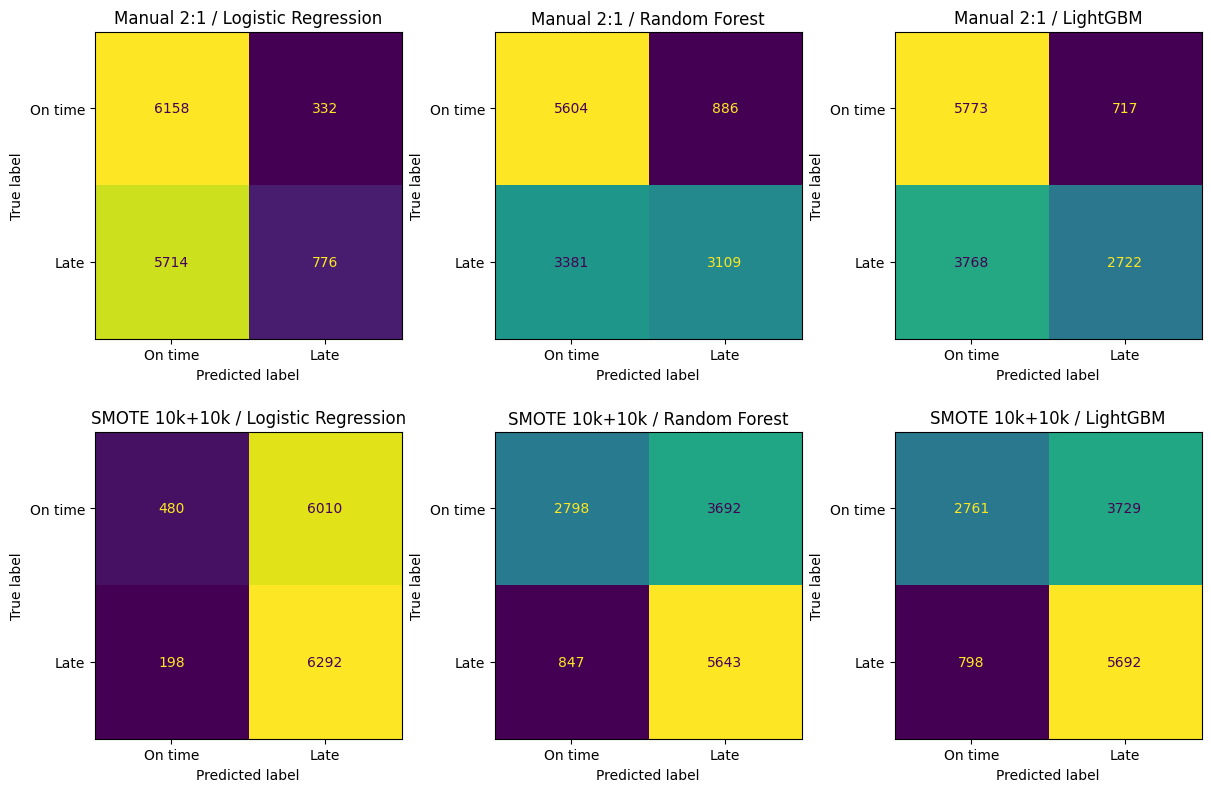

Kết quả được lưu tại: C:\DATAWARE-261\data-warehouse-ecommerce\notebooks\late_risk_results\balance_comparison


In [8]:
metrics = ["accuracy", "precision", "recall", "f1", "auc"]
grouped = results.groupby(["balance", "model"])[metrics]
summary = grouped.mean().map(lambda value: f"{value:.4f}")
summary += " ± " + grouped.std().map(lambda value: f"{value:.4f}")
display(summary)
summary.to_csv(OUTPUT / "summary.csv")

oof_records, class_reports, comparison = [], [], []
for (balance, name), subset in predictions.groupby(["balance", "model"]):
    oof_records.append(
        {
            "balance": balance,
            "model": name,
            "f1": f1_score(subset.late, subset.prediction),
            "auc": roc_auc_score(subset.late, subset.probability),
        }
    )
    report = classification_report(
        subset.late,
        subset.prediction,
        labels=[0, 1],
        target_names=["On time", "Late"],
        output_dict=True,
        zero_division=0,
    )
    report = pd.DataFrame(report).T.loc[["On time", "Late"]]
    report.index.name = "class"
    report = report.reset_index()
    report.insert(0, "model", name)
    report.insert(0, "balance", balance)
    class_reports.append(report)
    predicted_05 = (subset.probability >= 0.5).astype(int)
    comparison.append(
        {
            "balance": balance,
            "model": name,
            "threshold": 0.5,
            "precision": precision_score(subset.late, predicted_05),
            "recall": recall_score(subset.late, predicted_05),
            "f1": f1_score(subset.late, predicted_05),
            "auc": roc_auc_score(subset.late, subset.probability),
        }
    )

class_metrics = pd.concat(class_reports, ignore_index=True)
print("Chỉ số OOF riêng cho On time / Late:")
display(class_metrics.round(4))
class_metrics.to_csv(OUTPUT / "class_metrics.csv", index=False)
oof_metrics = pd.DataFrame(oof_records)
print("Điểm OOF: Manual ngưỡng 0,5; SMOTE ngưỡng validation đã chọn:")
display(oof_metrics.round(4))
oof_metrics.to_csv(OUTPUT / "oof_metrics.csv", index=False)

comparison_05 = pd.DataFrame(comparison)
print("So sánh Manual / SMOTE cùng ngưỡng 0,5:")
display(comparison_05.round(4))
comparison_05.to_csv(OUTPUT / "comparison_threshold_05.csv", index=False)

figure, axes = plt.subplots(2, 3, figsize=(12, 8), constrained_layout=True)
for row, balance in enumerate(["Manual 2:1", "SMOTE 10k+10k"]):
    for column, name in enumerate(models):
        subset = predictions.loc[
            predictions.balance.eq(balance) & predictions.model.eq(name)
        ]
        matrix = confusion_matrix(subset.late, subset.prediction)
        ConfusionMatrixDisplay(
            matrix, display_labels=["On time", "Late"]
        ).plot(ax=axes[row, column], colorbar=False, values_format="d")
        axes[row, column].set_title(f"{balance} / {name}")
figure.savefig(OUTPUT / "confusion_matrices.png", dpi=150)
plt.show()
print("Kết quả được lưu tại:", OUTPUT.resolve())


## 6. Kết quả tìm kiếm theo nhóm đã chạy

Đây là bản ghi của lượt tìm kiếm bổ sung, **không chạy lại khi Run All**.

Đã chạy 180 lượt thử + 10 lượt fit lại, khoảng 17,3 phút, trên cùng 5 fold/test 50:50.
Trong outer train tách 60% fit, 20% early stopping, 20% chọn config/ngưỡng;
chỉ chọn ngưỡng sau khi chốt config ở mức 0,5. LightGBM dùng LR=0,05, trần
2.000 cây, early stopping AUC với patience 50. Dừng một model nếu hai nhóm liên
tiếp không tăng F1 validation ít nhất 0,002; không dùng test để chọn config/ngưỡng.

| Model | F1 OOF chỉ config | F1 OOF thêm ngưỡng | AUC OOF |
|---|---:|---:|---:|
| LightGBM | 0.6092 | 0.7073 | 0.7596 |
| Random Forest | 0.5778 | 0.6762 | 0.6863 |

Lượt mới chưa vượt mốc LightGBM cũ F1=0,7155, nên dừng tìm kiếm và giữ luồng
chạy chính ở trên. Các config mới khác nhau theo fold, không có một config mới
thắng ổn định. File `late_risk_results/staged_tuning/choices.csv` ghi config/ngưỡng;
`search.csv` ghi mọi lượt thử; `fold_metrics.csv` và `oof_metrics.csv` ghi kết quả.
Không nhân thêm trọng số lớp cho LightGBM vì đã dùng SMOTE 10k+10k.

Đây là so sánh khám phá trên bộ dữ liệu đã dùng nhiều lần; lượt mới còn tách thêm
validation early stopping, nên không quy toàn bộ chênh lệch chỉ cho tham số.
